In [24]:
import pandas as pd
import numpy as np 
df = pd.read_csv('Carseats-1.csv', usecols=[1,6,10,11])
df

,Sales,Price,Urban,US
0,9.50,120,Yes,Yes
1,11.22,83,Yes,Yes
2,10.06,80,Yes,Yes
3,7.40,97,Yes,Yes
4,4.15,128,Yes,No
...,...,...,...,...
395,12.57,128,Yes,Yes
396,6.14,120,No,Yes
397,7.41,159,Yes,Yes
398,5.94,95,Yes,Yes


In [ ]:
# Making mapping dict
# Turning Urban category into numerical values
urban_mapping = {label: idx for idx, label in enumerate(np.unique(df['Urban']))}
urban_mapping

{'No': 0, 'Yes': 1}

In [5]:
# Repeat for US
us_mapping = {label: idx for idx, label in enumerate(np.unique(df['US']))}
us_mapping

{'No': 0, 'Yes': 1}

In [6]:
df['Urban'] = df['Urban'].map(urban_mapping)
df['US'] = df['US'].map(urban_mapping)
df

,Sales,Price,Urban,US
0,9.50,120,1,1
1,11.22,83,1,1
2,10.06,80,1,1
3,7.40,97,1,1
4,4.15,128,1,0
...,...,...,...,...
395,12.57,128,1,1
396,6.14,120,0,1
397,7.41,159,1,1
398,5.94,95,1,1


In [7]:
X = df.loc[:,['Price','Urban','US']]
y = df['Sales']
display(X)
display(y)

,Price,Urban,US
0,120,1,1
1,83,1,1
2,80,1,1
3,97,1,1
4,128,1,0
...,...,...,...
395,128,1,1
396,120,0,1
397,159,1,1
398,95,1,1


0       9.50
1      11.22
2      10.06
3       7.40
4       4.15
       ...  
395    12.57
396     6.14
397     7.41
398     5.94
399     9.71
Name: Sales, Length: 400, dtype: float64

In [32]:
import time
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# The base hyperparameters for our gradient boosting regression.
# By default, our loss = squared_error.
# This means that the loss function we use in place in the Gradient Boosting algorithm
# is the squared error function.
params = dict(n_estimators=1000, max_depth=3, learning_rate=0.1, random_state=42)#, max_features = 5)

X_train, X_val, y_train, y_val = train_test_split(X, y, 
                                                    test_size = 0.2, 
                                                    random_state = 42)

In [33]:
param_dist = {
    'learning_rate': np.arange(0.1, 0.2, 0.01), 
    'n_estimators': [100, 200, 300, 400],  
    'max_depth': [3, 5, 7, 9],  
}

gb_model = GradientBoostingRegressor()

random_search = RandomizedSearchCV(estimator=gb_model, param_distributions=param_dist, n_iter=10, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)

random_search.fit(X_train, y_train)

best_params = random_search.best_params_
best_model = random_search.best_estimator_

y_pred_best = best_model.predict(X_val)

mse_best = mean_squared_error(y_val, y_pred_best)

print("Best Parameters:", best_params)
print(f"Best Model MSE: {mse_best}")

Best Parameters: {'n_estimators': 100, 'max_depth': 3, 'learning_rate': np.float64(0.12)}
Best Model MSE: 10.025893665425205


In [35]:
gbm_full = GradientBoostingRegressor(**params)
gbm_early_stopping = GradientBoostingRegressor(
    **params,

    # ! These are our early stopping parameters ! #
    validation_fraction=0.1,
    n_iter_no_change=10,
)


start_time = time.time()
gbm_full.fit(X_train, y_train)
pred_y_full = gbm_full.predict(X_val)
training_time_full = time.time() - start_time
n_estimators_full = gbm_full.n_estimators_

start_time = time.time()
gbm_early_stopping.fit(X_train, y_train)
pred_y_early_stopping = gbm_early_stopping.predict(X_val)
training_time_early_stopping = time.time() - start_time
estimators_early_stopping = gbm_early_stopping.n_estimators_

In [36]:
train_errors_without = []
val_errors_without = []

train_errors_with = []
val_errors_with = []

for i, (train_pred, val_pred) in enumerate(
    zip(
        gbm_full.staged_predict(X_train),
        gbm_full.staged_predict(X_val),
    )
):
    train_errors_without.append(mean_squared_error(y_train, train_pred))
    val_errors_without.append(mean_squared_error(y_val, val_pred))

for i, (train_pred, val_pred) in enumerate(
    zip(
        gbm_early_stopping.staged_predict(X_train),
        gbm_early_stopping.staged_predict(X_val),
    )
):
    train_errors_with.append(mean_squared_error(y_train, train_pred))
    val_errors_with.append(mean_squared_error(y_val, val_pred))

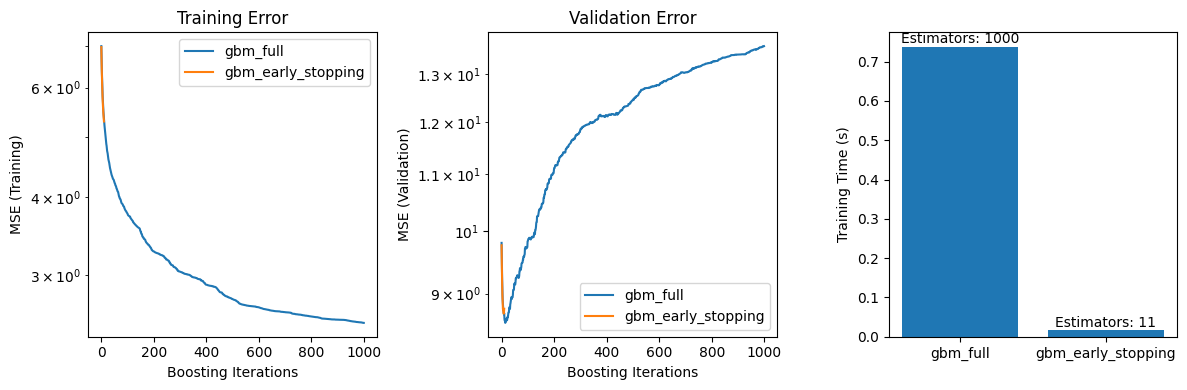

In [37]:
fig, axes = plt.subplots(ncols=3, figsize=(12, 4))

axes[0].plot(train_errors_without, label="gbm_full")
axes[0].plot(train_errors_with, label="gbm_early_stopping")
axes[0].set_xlabel("Boosting Iterations")
axes[0].set_ylabel("MSE (Training)")
axes[0].set_yscale("log")
axes[0].legend()
axes[0].set_title("Training Error")

axes[1].plot(val_errors_without, label="gbm_full")
axes[1].plot(val_errors_with, label="gbm_early_stopping")
axes[1].set_xlabel("Boosting Iterations")
axes[1].set_ylabel("MSE (Validation)")
axes[1].set_yscale("log")
axes[1].legend()
axes[1].set_title("Validation Error")

training_times = [training_time_full, training_time_early_stopping]
labels = ["gbm_full", "gbm_early_stopping"]
bars = axes[2].bar(labels, training_times)
axes[2].set_ylabel("Training Time (s)")

for bar, n_estimators in zip(bars, [n_estimators_full, estimators_early_stopping]):
    height = bar.get_height()
    axes[2].text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.001,
        f"Estimators: {n_estimators}",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

In [38]:
test_rmse_full = mean_squared_error(y_val, pred_y_full) ** (1 / 2)
test_rmse_early_stopping = mean_squared_error(y_val, pred_y_early_stopping) ** (1 / 2)

print('Root mean Square error (full): {:.5f}'.format(test_rmse_full))
print('Root mean Square error (early stopping): {:.5f}'.format(test_rmse_early_stopping))

Root mean Square error (full): 3.69207
Root mean Square error (early stopping): 2.96236
